# 01 · SQL exploration and cleaning

> **Illustrative scenario.** The business framing is invented. The data is real (a UK online gift retailer, 2009-2011, with many wholesale buyers) and contains **no marketing contact data**, so the outcome studied here is *ordering again within 90 days*, not response to marketing.

**Purpose.** Check data quality, decide and justify each cleaning rule with its volume, describe customers and seasonality, confirm event counts for every snapshot window, and check that repeat-purchase rates are not uniform across simple customer groups before any segmentation is built.

All cleaning and feature logic runs as SQL in DuckDB (`sql/01`-`03`). Numbers in this notebook come from code output, not typed text.

In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

from segmentation_propensity.data import clean_lines, connect, flag_counts, load_raw
from segmentation_propensity.features import FEATURES, build_all_snapshots, snapshot_summary
from segmentation_propensity.utils import load_config, resolve, set_seed

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3})

cfg = load_config(Path("..") / "config.yaml")
set_seed(cfg["project"]["seed"])
FIG = resolve(cfg, "figures_dir")
FIG.mkdir(parents=True, exist_ok=True)

con = connect(cfg)
raw = load_raw(cfg)
print(f"Raw lines: {len(raw):,} | columns: {raw.shape[1]}")
print(f"Invoice dates: {raw.InvoiceDate.min()} to {raw.InvoiceDate.max()}")

Raw lines: 1,067,371 | columns: 8
Invoice dates: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


## 1. Data quality
Missing values by column, then every flag counted independently (a line can carry several flags).

In [2]:
quality = pd.DataFrame({"missing": raw.isna().sum(), "missing_pct": (100 * raw.isna().mean()).round(2), "dtype": raw.dtypes.astype(str)})
quality

,missing,missing_pct,dtype
Invoice,0,0.00,object
StockCode,0,0.00,object
Description,4382,0.41,object
Quantity,0,0.00,int64
InvoiceDate,0,0.00,datetime64[ns]
Price,0,0.00,float64
Customer ID,243007,22.77,float64
Country,0,0.00,object


In [3]:
clog = clean_lines(con, raw, cfg)
flags = flag_counts(con)
print("Independent flag counts (overlapping):")
for k, v in flags.items():
    print(f"  {k:<26} {v:>9,}  ({100 * v / len(raw):.2f}% of lines)")
missing_value_share = con.execute(
    """SELECT sum(CASE WHEN status = 'missing_customer_id' AND quantity > 0 AND price > 0 THEN line_value END)
           / sum(CASE WHEN quantity > 0 AND price > 0 THEN line_value END) FROM line_status"""
).fetchone()[0]
print(f"\nPositive sales value on lines without a Customer ID: {100 * missing_value_share:.1f}%")

Independent flag counts (overlapping):
  cancellation                  19,494  (1.83% of lines)
  missing_customer_id          243,007  (22.77% of lines)
  non_product_code               5,925  (0.56% of lines)
  price_le_zero                  6,207  (0.58% of lines)
  neg_qty_non_cancellation       3,457  (0.32% of lines)
  exact_duplicate               34,335  (3.22% of lines)

Positive sales value on lines without a Customer ID: 15.4%


### Cleaning waterfall
Each line gets exactly one status in priority order (see `sql/01_clean_lines.sql`). Value is the absolute line value.

In [4]:
clog.assign(abs_value=clog.abs_value.round(0), share_of_lines=(100 * clog.share_of_lines).round(2), share_of_value=(100 * clog.share_of_value).round(2))

,status,lines,abs_value,share_of_lines,share_of_value
0,missing_customer_id,243007,3820120.0,22.77,16.86
1,non_product_code,3736,684448.0,0.35,3.02
2,price_le_zero,61,0.0,0.01,0.00
3,exact_duplicate,26402,375582.0,2.47,1.66
4,reversed_giant_line,10,495098.0,0.00,2.19
5,cancellation,17581,462404.0,1.65,2.04
6,purchase,776574,16821034.0,72.76,74.24


### Checks behind two rules
1. **Non-product codes.** The exclusion list is explicit. Any non-standard code still among purchases is listed so it can be reviewed rather than dropped by a pattern.
2. **Giant lines.** Lines of 5,000+ units, by final status. A purchase that is later cancelled one-for-one (same customer, product, quantity and price) is removed on both sides.

In [5]:
leftover = con.execute(
    """SELECT stock_code, any_value(description) AS description, count(*) AS lines, round(sum(line_value), 2) AS value
       FROM line_status WHERE status = 'purchase' AND NOT regexp_matches(stock_code, '^[0-9]{5}[A-Za-z]{0,2}$')
       GROUP BY 1 ORDER BY lines DESC"""
).df()
print("Non-standard codes left among purchases:")
print(leftover.to_string(index=False) if len(leftover) else "  none")
giant = con.execute(
    """SELECT status, count(*) AS lines, max(abs(quantity)) AS max_abs_qty, round(sum(abs(line_value)), 0) AS abs_value
       FROM line_status WHERE abs(quantity) >= 5000 GROUP BY 1 ORDER BY lines DESC"""
).df()
giant

Non-standard codes left among purchases:
stock_code            description  lines  value
    SP1002 KID'S CHALKBOARD/EASEL      2  14.75


,status,lines,max_abs_qty,abs_value
0,missing_customer_id,33,10200,0.0
1,purchase,27,19152,51610.0
2,reversed_giant_line,10,80995,495098.0
3,cancellation,1,9360,281.0
4,exact_duplicate,1,9360,281.0
5,price_le_zero,1,12540,0.0


### Duplicate sensitivity
Snapshot event counts with exact duplicates kept versus dropped. If the choice barely changes events, it cannot drive the results.

In [6]:
snaps = build_all_snapshots(con, cfg)
summary = snapshot_summary(snaps, cfg)
con_keep = connect(cfg)
clean_lines(con_keep, raw, cfg, drop_duplicates=False)
summary_keep = snapshot_summary(build_all_snapshots(con_keep, cfg), cfg)
dup_check = summary[["snapshot", "customers", "events"]].merge(
    summary_keep[["snapshot", "customers", "events"]], on="snapshot", suffixes=("_dropped", "_kept")
)
dup_check

,snapshot,customers_dropped,events_dropped,customers_kept,events_kept
0,seasonal_2010,3243,1898,3243,1898
1,dev,3856,1539,3856,1539
2,val,3905,1503,3905,1503
3,test,3238,1868,3238,1868


## 2. Orders, products and countries

Purchase invoices: 36,592 | customers: 5,852 | products: 4,619
          value     lines  units_per_line
count  36592.00  36592.00        36592.00
mean     459.69     21.22           26.03
std      955.66     22.97          142.33
min        0.38      1.00            1.00
10%       85.00      2.00            2.00
50%      302.54     15.00            9.00
90%      824.41     47.00           36.00
99%     3525.71    105.00          360.00
max    44051.60    541.00        10000.00


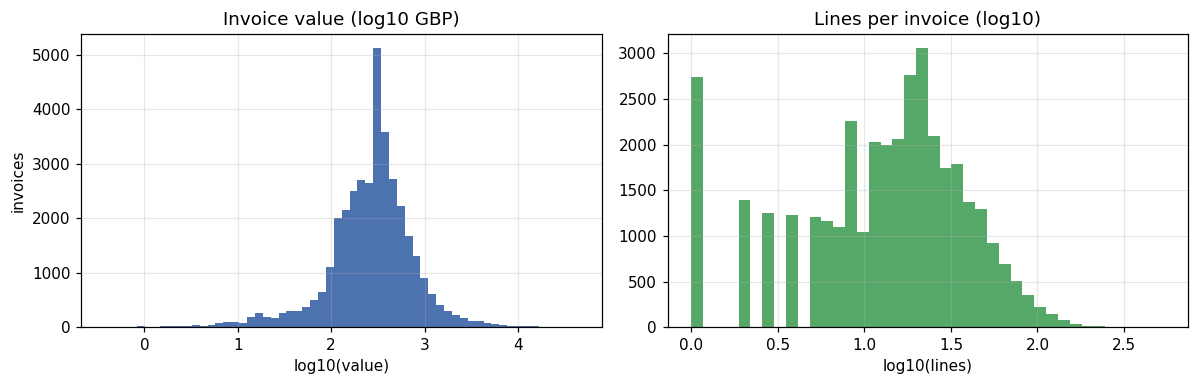

In [7]:
inv = con.execute(
    """SELECT invoice, customer_id, min(invoice_ts) AS ts, sum(line_value) AS value, count(*) AS lines, median(quantity) AS units_per_line
       FROM purchases GROUP BY invoice, customer_id"""
).df()
print(f"Purchase invoices: {len(inv):,} | customers: {inv.customer_id.nunique():,} | products: {con.execute('SELECT count(DISTINCT stock_code) FROM purchases').fetchone()[0]:,}")
print(inv[["value", "lines", "units_per_line"]].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(np.log10(inv.value.clip(lower=0.01)), bins=60, color="#4C72B0")
ax[0].set(title="Invoice value (log10 GBP)", xlabel="log10(value)", ylabel="invoices")
ax[1].hist(np.log10(inv.lines), bins=40, color="#55A868")
ax[1].set(title="Lines per invoice (log10)", xlabel="log10(lines)")
fig.tight_layout(); fig.savefig(FIG / "eda_invoice_distributions.png")

In [8]:
countries = con.execute(
    """WITH c AS (SELECT customer_id, arg_max(country, n) AS country FROM (SELECT customer_id, country, count(*) n FROM purchases GROUP BY 1, 2) GROUP BY 1)
       SELECT country, count(*) AS customers FROM c GROUP BY 1 ORDER BY customers DESC"""
).df()
countries["share_pct"] = (100 * countries.customers / countries.customers.sum()).round(1)
countries.head(8)

,country,customers,share_pct
0,United Kingdom,5334,91.1
1,Germany,106,1.8
2,France,93,1.6
3,Spain,35,0.6
4,Belgium,28,0.5
5,Portugal,23,0.4
6,Netherlands,22,0.4
7,Switzerland,22,0.4


## 3. Seasonality
Monthly sales value and active customers. The test label window (September to December 2011) sits on the seasonal peak, which is why the analysis plan adds a same-season 2010 window and a Q4 flag.

Share of sales value in Sep-Dec months: 44.3% (4 of 12 months = 33.3%)


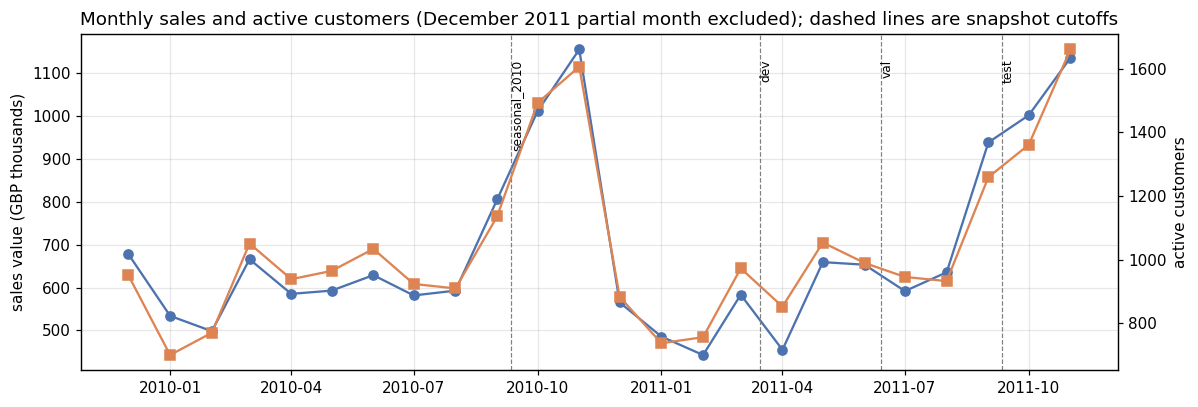

In [9]:
monthly = con.execute(
    """SELECT date_trunc('month', invoice_ts) AS month, sum(line_value) AS value, count(DISTINCT customer_id) AS customers,
              count(DISTINCT invoice) AS invoices
       FROM purchases WHERE invoice_ts < TIMESTAMP '2011-12-01' GROUP BY 1 ORDER BY 1"""
).df()
fig, ax1 = plt.subplots(figsize=(11, 3.8))
ax1.plot(monthly.month, monthly.value / 1e3, marker="o", color="#4C72B0", label="sales value (GBP k)")
ax1.set_ylabel("sales value (GBP thousands)")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(monthly.month, monthly.customers, marker="s", color="#DD8452", label="active customers")
ax2.set_ylabel("active customers")
for name, s in cfg["windows"]["snapshots"].items():
    ax1.axvline(pd.Timestamp(s["cutoff"]), color="grey", ls="--", lw=0.8)
    ax1.text(pd.Timestamp(s["cutoff"]), ax1.get_ylim()[1] * 0.95, name, rotation=90, va="top", fontsize=8)
ax1.set_title("Monthly sales and active customers (December 2011 partial month excluded); dashed lines are snapshot cutoffs")
fig.tight_layout(); fig.savefig(FIG / "eda_monthly_seasonality.png")
monthly["q4"] = monthly.month.dt.month.isin([9, 10, 11, 12])
print(f"Share of sales value in Sep-Dec months: {100 * monthly.loc[monthly.q4, 'value'].sum() / monthly.value.sum():.1f}% (4 of 12 months = 33.3%)")

## 4. Wholesale profile
How concentrated is value, and how many customers buy in trade quantities?

Customers: 5,852
Top 1% of customers hold 31.3% of sales value
Customers with median units per line >= 12: 33.5%


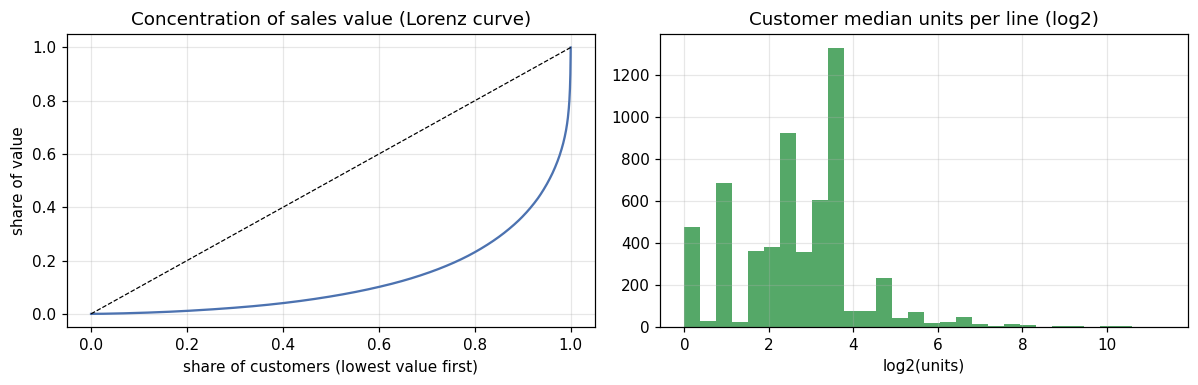

In [10]:
cust = con.execute(
    """SELECT customer_id, sum(line_value) AS value, median(quantity) AS median_units_per_line FROM purchases GROUP BY 1"""
).df().sort_values("value", ascending=False)
top1 = cust.value.head(max(1, len(cust) // 100)).sum() / cust.value.sum()
wh = (cust.median_units_per_line >= cfg["cleaning"]["wholesale_units_per_line"]).mean()
print(f"Customers: {len(cust):,}")
print(f"Top 1% of customers hold {100 * top1:.1f}% of sales value")
print(f"Customers with median units per line >= {cfg['cleaning']['wholesale_units_per_line']}: {100 * wh:.1f}%")
lorenz = np.r_[0, np.cumsum(np.sort(cust.value.to_numpy())) / cust.value.sum()]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.linspace(0, 1, len(lorenz)), lorenz, color="#4C72B0"); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title="Concentration of sales value (Lorenz curve)", xlabel="share of customers (lowest value first)", ylabel="share of value")
ax[1].hist(np.log2(cust.median_units_per_line.clip(lower=1)), bins=30, color="#55A868")
ax[1].set(title="Customer median units per line (log2)", xlabel="log2(units)")
fig.tight_layout(); fig.savefig(FIG / "eda_wholesale_profile.png")

## 5. Snapshot windows and events
Features use the 273 days before each cutoff; the label is any purchase in the 90 days after it. Counts are checked against the counts from the initial feasibility check (gate: within 5%) and the 50-events-per-fold minimum.

In [11]:
SPEC = {"seasonal_2010": (3243, 1898), "dev": (3856, 1539), "val": (3906, 1503), "test": (3239, 1869)}
summary["spec_customers"] = summary.snapshot.map(lambda s: SPEC[s][0])
summary["spec_events"] = summary.snapshot.map(lambda s: SPEC[s][1])
summary["events_diff_pct"] = (100 * (summary.events / summary.spec_events - 1)).round(2)
summary["within_5pct"] = summary.events_diff_pct.abs() <= 5
summary["fold_ok"] = summary.events_per_fold >= cfg["evaluation"]["min_events_per_fold"]
assert summary.within_5pct.all() and summary.fold_ok.all()
summary.round(3)

,snapshot,cutoff,customers,events,non_events,event_rate,events_per_fold,spec_customers,spec_events,events_diff_pct,within_5pct,fold_ok
0,seasonal_2010,2010-09-11,3243,1898,1345,0.585,379,3243,1898,0.00,True,True
1,dev,2011-03-15,3856,1539,2317,0.399,307,3856,1539,0.00,True,True
2,val,2011-06-13,3905,1503,2402,0.385,300,3906,1503,0.00,True,True
3,test,2011-09-11,3238,1868,1370,0.577,373,3239,1869,-0.05,True,True


## 6. Is there something to segment? (dev window only)
Repeat-purchase rate across simple groups. If every group had the same rate, segmentation could not separate outcomes and the owner would be warned before modelling. Only the dev snapshot is used here; no test-window outcomes are examined beyond the event counts above.

In [12]:
dev = snaps["dev"].copy()
dev["wholesale_profile"] = (dev.median_units_per_line >= cfg["cleaning"]["wholesale_units_per_line"]).astype(int)
groups = {
    "recency quintile": pd.qcut(dev.recency_days.rank(method="first"), 5, labels=["most recent", "2", "3", "4", "least recent"]),
    "frequency quintile": pd.qcut(dev.frequency_invoices.rank(method="first"), 5, labels=["lowest", "2", "3", "4", "highest"]),
    "monetary quintile": pd.qcut(dev.monetary_net_gbp.rank(method="first"), 5, labels=["lowest", "2", "3", "4", "highest"]),
    "wholesale profile": dev.wholesale_profile.map({0: "no", 1: "yes"}),
    "UK customer": dev.is_uk.map({0: "no", 1: "yes"}),
}
rows, rates = [], {}
for name, g in groups.items():
    t = pd.crosstab(g, dev.y)
    chi2, p, dof, _ = chi2_contingency(t)
    rows.append({"variable": name, "chi2": round(chi2, 1), "dof": dof, "p": p, "cramers_v": round(np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1))), 3)})
    rates[name] = (t[1] / t.sum(1)).round(3)
signal = pd.DataFrame(rows)
print(f"Dev window: {len(dev):,} customers, repeat-purchase rate {dev.y.mean():.3f}")
print("Uniform outcome rates across every group?", "YES - warn owner" if (signal.p >= 0.05).all() else "no")
signal

Dev window: 3,856 customers, repeat-purchase rate 0.399
Uniform outcome rates across every group? no


,variable,chi2,dof,p,cramers_v
0,recency quintile,496.7,4,3.380802e-106,0.359
1,frequency quintile,752.6,4,1.438888e-161,0.442
2,monetary quintile,656.2,4,1.083423e-140,0.413
3,wholesale profile,4.7,1,3.000754e-02,0.035
4,UK customer,0.4,1,5.073849e-01,0.011


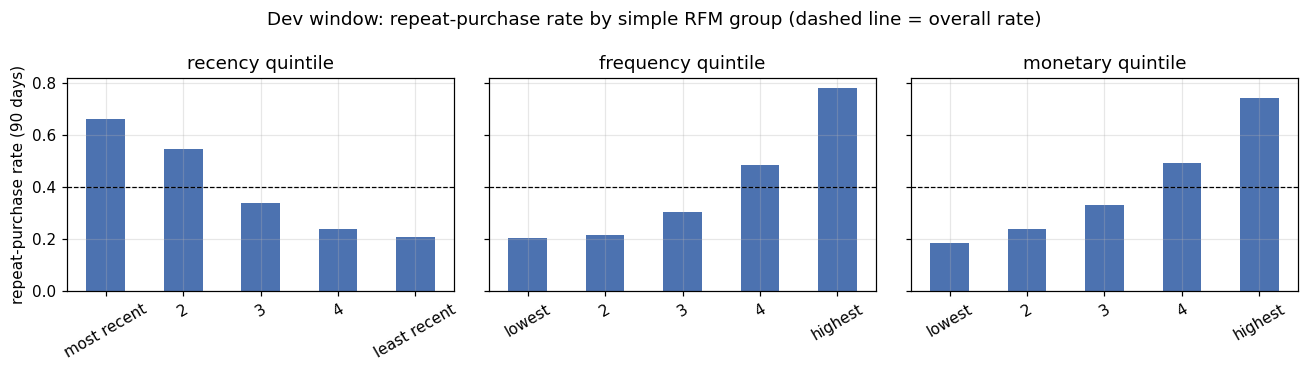

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, name in zip(axes, ["recency quintile", "frequency quintile", "monetary quintile"]):
    rates[name].plot.bar(ax=ax, color="#4C72B0")
    ax.axhline(dev.y.mean(), color="k", ls="--", lw=0.8)
    ax.set(title=name, xlabel="", ylabel="repeat-purchase rate (90 days)")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Dev window: repeat-purchase rate by simple RFM group (dashed line = overall rate)")
fig.tight_layout(); fig.savefig(FIG / "eda_repurchase_by_rfm_group.png")

### Feature correlations and skew (dev window)
Highly correlated pairs (|Spearman ρ| > 0.85) are flagged for the modelling phase. Skew before and after `log1p` shows why the analysis plan log-transforms value and count features.

Pairs with |rho| > 0.85: [('frequency_invoices', 'active_months', np.float64(0.948)), ('frequency_invoices', 'mean_interpurchase_days', np.float64(-0.857)), ('frequency_invoices', 'single_invoice_flag', np.float64(-0.879)), ('mean_interpurchase_days', 'single_invoice_flag', np.float64(0.874))]


,skew_raw,skew_log1p
frequency_invoices,10.10,1.34
frequency_invoices_last_90d,6.61,1.37
monetary_net_gbp,20.79,-0.10
avg_order_value_gbp,11.91,-0.05
avg_lines_per_invoice,2.64,-0.43
median_units_per_line,21.64,1.11
n_distinct_products,5.99,-0.30
active_months,1.68,0.82
mean_interpurchase_days,0.26,-0.98


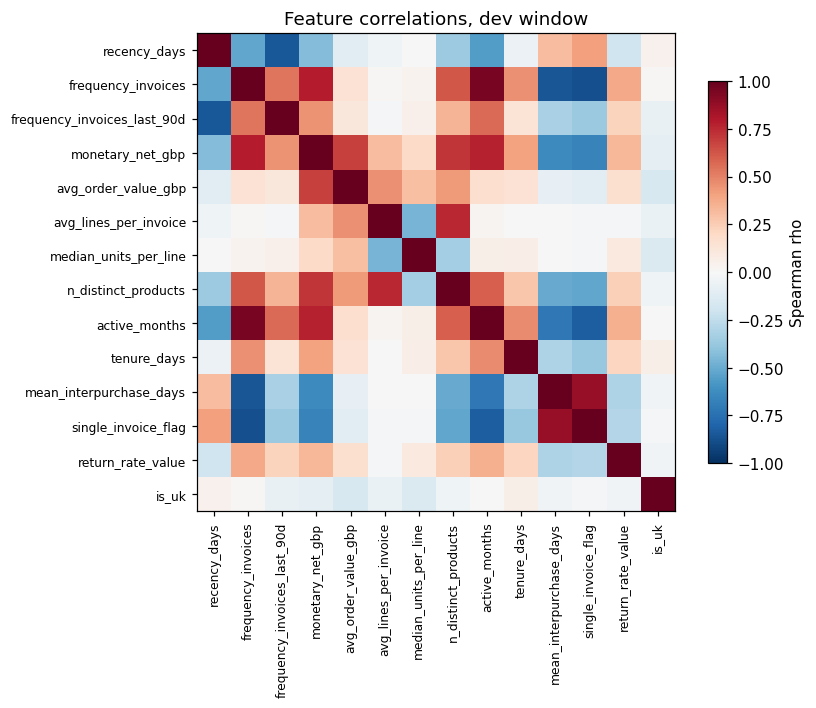

In [14]:
num = [f for f in FEATURES if f != "label_window_q4"]
rho = pd.DataFrame(spearmanr(dev[num]).statistic, index=num, columns=num)
pairs = [(a, b, round(rho.loc[a, b], 3)) for i, a in enumerate(num) for b in num[i + 1:] if abs(rho.loc[a, b]) > 0.85]
print("Pairs with |rho| > 0.85:", pairs if pairs else "none")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=90, fontsize=8); ax.set_yticks(range(len(num)), num, fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=0.8, label="Spearman rho"); ax.set_title("Feature correlations, dev window")
fig.tight_layout(); fig.savefig(FIG / "eda_feature_correlations.png")
skew = pd.DataFrame({"skew_raw": dev[cfg["features"]["log1p"]].skew(), "skew_log1p": np.log1p(dev[cfg["features"]["log1p"]].clip(lower=0)).skew()}).round(2)
skew

## 7. Issues and cleaning plan
The table below is generated from the results above. Rules live in `config.yaml` and `sql/01_clean_lines.sql`.

In [15]:
status_lines = clog.set_index(clog.status.astype(str)).lines
plan = pd.DataFrame([
    ("Missing Customer ID", f"{status_lines['missing_customer_id']:,} lines; {100 * missing_value_share:.1f}% of sales value", "Exclude", "Cannot be attributed to a customer; segments describe registered customers only"),
    ("Non-product codes", f"{status_lines['non_product_code']:,} lines", "Exclude (explicit list)", "Postage, fees, adjustments and vouchers are not product demand"),
    ("Price <= 0", f"{status_lines['price_le_zero']:,} lines after earlier rules", "Exclude", "Free items and adjustments"),
    ("Negative quantity, no 'C'", f"{flags['neg_qty_non_cancellation']:,} flagged; all also lack a Customer ID", "Exclude", "Stock adjustments"),
    ("Exact duplicates", f"{status_lines['exact_duplicate']:,} lines", "Drop" + (" (customers and events identical when kept)" if (dup_check.events_dropped == dup_check.events_kept).all() else " (events differ when kept: see check)"), "Duplicate records inflate frequency and value"),
    ("Giant reversed lines", f"{status_lines['reversed_giant_line']:,} lines", "Remove purchase and its matching cancellation", "Mistaken orders would distort order value and units per line"),
    ("Cancellations", f"{status_lines['cancellation']:,} lines", "Not purchases; net from value; return-rate feature", "Return behaviour is a customer trait"),
    ("Wholesale concentration", f"top 1% hold {100 * top1:.1f}% of value", "Keep; log1p and winsorise at dev 99.5th percentile in the segmentation step", "They are the business, but unscaled they would dominate clusters"),
], columns=["issue", "volume", "rule", "reason"])
plan

,issue,volume,rule,reason
0,Missing Customer ID,"243,007 lines; 15.4% of sales value",Exclude,Cannot be attributed to a customer; segments d...
1,Non-product codes,"3,736 lines",Exclude (explicit list),"Postage, fees, adjustments and vouchers are no..."
2,Price <= 0,61 lines after earlier rules,Exclude,Free items and adjustments
3,"Negative quantity, no 'C'","3,457 flagged; all also lack a Customer ID",Exclude,Stock adjustments
4,Exact duplicates,"26,402 lines",Drop (customers and events identical when kept),Duplicate records inflate frequency and value
5,Giant reversed lines,10 lines,Remove purchase and its matching cancellation,Mistaken orders would distort order value and ...
6,Cancellations,"17,581 lines",Not purchases; net from value; return-rate fea...,Return behaviour is a customer trait
7,Wholesale concentration,top 1% hold 31.3% of value,Keep; log1p and winsorise at dev 99.5th percen...,"They are the business, but unscaled they would..."


## 8. Key findings for the checkpoint

In [16]:
test_row = summary.set_index("snapshot").loc["test"]
rec = rates["recency quintile"]
findings = [
    f"Cleaning keeps {status_lines['purchase']:,} purchase lines ({100 * clog.set_index(clog.status.astype(str)).share_of_lines['purchase']:.1f}% of raw lines); the biggest loss is lines without a Customer ID ({100 * missing_value_share:.1f}% of sales value).",
    f"Value is concentrated: the top 1% of customers hold {100 * top1:.1f}% of sales value and {100 * wh:.1f}% of customers buy a median of {cfg['cleaning']['wholesale_units_per_line']}+ units per line.",
    f"Strong seasonality: Sep-Dec months carry {100 * monthly.loc[monthly.q4, 'value'].sum() / monthly.value.sum():.1f}% of sales value; the test window's repeat-purchase rate is {test_row.event_rate:.3f} against {summary.set_index('snapshot').loc['dev', 'event_rate']:.3f} in dev.",
    f"Repeat-purchase rates are far from uniform in dev: from {rec.iloc[0]:.3f} in the most recent recency quintile to {rec.iloc[-1]:.3f} in the least recent (Cramer's V {signal.set_index('variable').loc['recency quintile', 'cramers_v']}).",
    f"Every window has enough events: test {int(test_row.events):,} buyers and {int(test_row.non_events):,} non-buyers; smallest CV fold {int(summary.events_per_fold.min())} events (minimum {cfg['evaluation']['min_events_per_fold']}).",
]
for f in findings:
    print("-", f)

- Cleaning keeps 776,574 purchase lines (72.8% of raw lines); the biggest loss is lines without a Customer ID (15.4% of sales value).
- Value is concentrated: the top 1% of customers hold 31.3% of sales value and 33.5% of customers buy a median of 12+ units per line.
- Strong seasonality: Sep-Dec months carry 44.3% of sales value; the test window's repeat-purchase rate is 0.577 against 0.399 in dev.
- Repeat-purchase rates are far from uniform in dev: from 0.661 in the most recent recency quintile to 0.210 in the least recent (Cramer's V 0.359).
- Every window has enough events: test 1,868 buyers and 1,370 non-buyers; smallest CV fold 300 events (minimum 50).
